EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

project_dir = Path.cwd().resolve().parent
data_dir = project_dir / "data"
figures_dir = project_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

expression = pd.read_csv(
    data_dir / "expression_normalized.csv",
    index_col=0
)

metadata = pd.read_csv(
    data_dir / "metadata_normalized.csv",
    dtype={"Sample_ID": str}
)

expression.columns = expression.columns.astype(str)

metadata = metadata.set_index("Sample_ID")
metadata = metadata.loc[expression.columns]

print("Expression matrix:", expression.shape)
print("\nSample groups:")
print(metadata["Group"].value_counts())

Expression matrix: (730, 32)

Sample groups:
Group
Early-onset PE    13
Healthy           13
Late-onset PE      6
Name: count, dtype: int64


In [2]:
# Log2 transform normalized expression values
log_expression = np.log2(expression + 1)

print("Log-transformed matrix:", log_expression.shape)

display(log_expression.iloc[:5, :5])

Log-transformed matrix: (730, 32)


,136,137,161,170,172
ID_REF,,,,,
A2M,13.623272,13.671902,13.352020,13.162990,13.359791
ABCB1,11.439883,11.919737,11.891374,11.272962,11.534033
ABL1,9.397008,9.295957,9.384804,9.108224,9.156433
ADA,6.265130,7.459977,6.427304,5.384020,5.689415
ADORA2A,4.854978,4.976379,5.223514,4.859070,4.717104


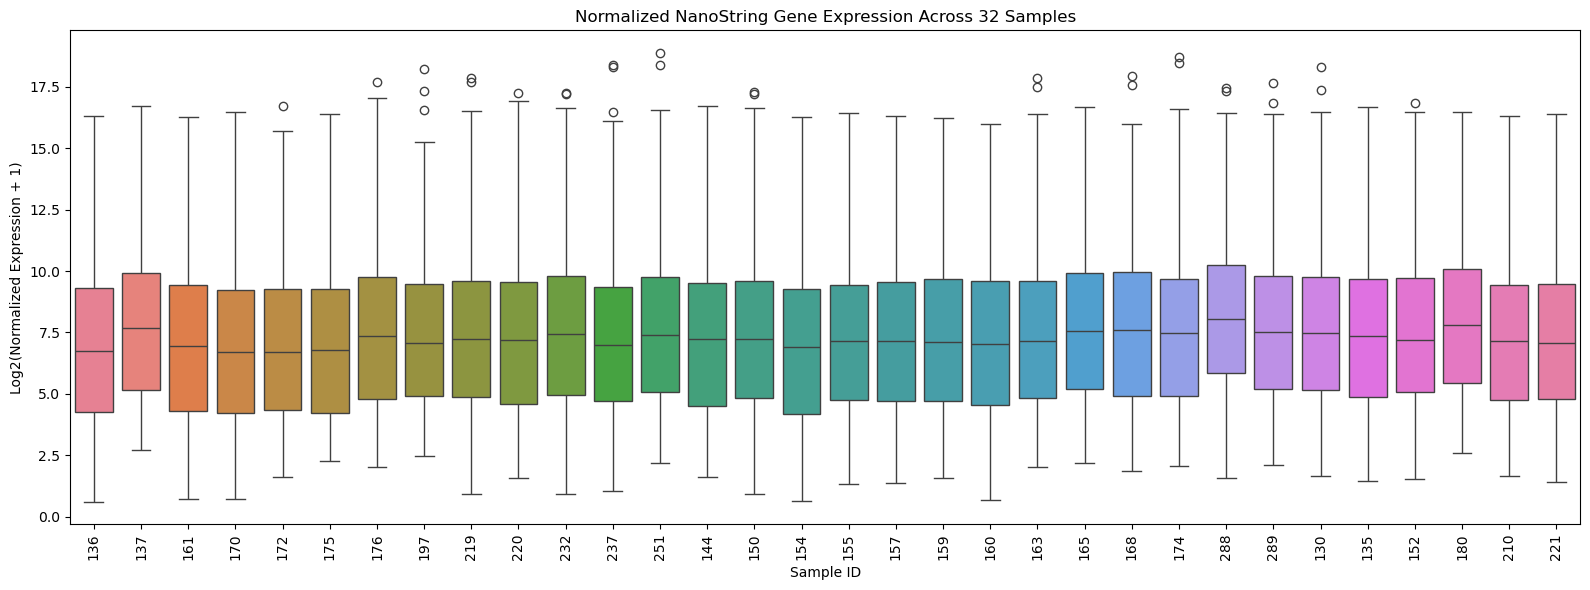

In [3]:
plt.figure(figsize=(16, 6))

sns.boxplot(data=log_expression)

plt.title(
    "Normalized NanoString Gene Expression Across 32 Samples"
)

plt.xlabel("Sample ID")
plt.ylabel("Log2(Normalized Expression + 1)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    figures_dir / "normalized_expression_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PCA

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Transpose matrix: samples as rows, genes as columns
X = log_expression.T

# Standardize gene expression
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Create PCA dataframe
pca_df = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"],
    index=X.index
)

# Add group labels
pca_df["Group"] = metadata.loc[pca_df.index, "Group"]

print("Explained variance:")
print("PC1:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")

display(pca_df.head())

Explained variance:
PC1: 26.83 %
PC2: 10.4 %


,PC1,PC2,Group
136,-22.613720,-6.184477,Early-onset PE
137,16.167569,-3.155026,Early-onset PE
161,-15.572898,-3.551453,Early-onset PE
170,-22.282062,1.803391,Early-onset PE
172,-21.188619,3.574773,Early-onset PE


Standard scaler is used so the genes with higher expression values don't automatically dominate PCA. 

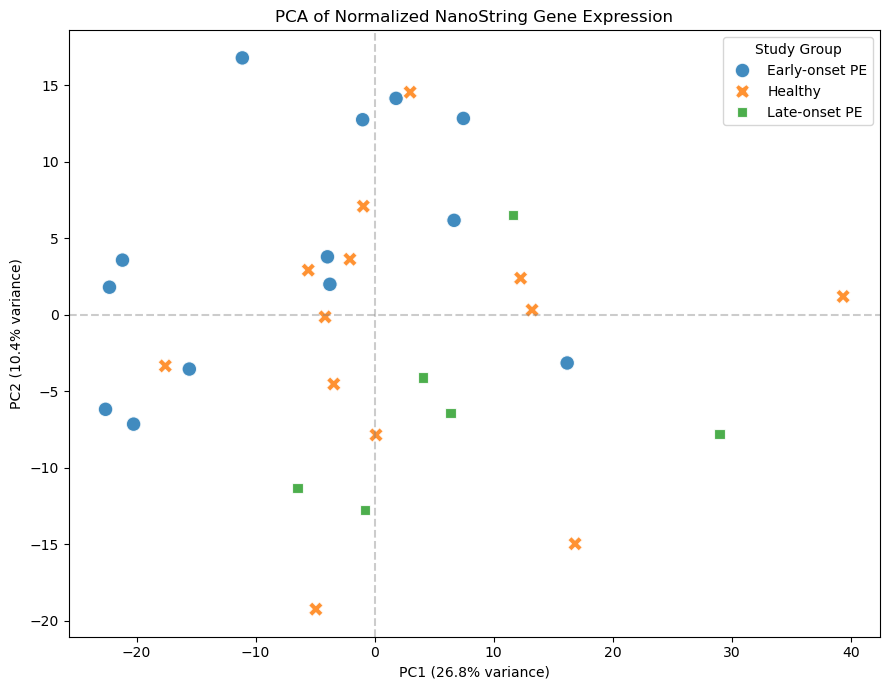

In [5]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Group",
    style="Group",
    s=110,
    alpha=0.85
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"
)

plt.title(
    "PCA of Normalized NanoString Gene Expression"
)

plt.axhline(0, color="gray", linestyle="--", alpha=0.4)
plt.axvline(0, color="gray", linestyle="--", alpha=0.4)

plt.legend(title="Study Group")
plt.tight_layout()

plt.savefig(
    figures_dir / "PCA_NanoString_GSE190639.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

More of the early onset samples cluster towards the negative PC1 values and a lot of the several late onset samples are located towards the postive PC1 values.

In [15]:
# Save PCA results
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

pca_df.to_csv(results_dir / "pca_results.csv")

print("PCA results saved successfully!")
print("File location:", results_dir / "pca_results.csv")

PCA results saved successfully!
File location: /Users/tavimangoma/Documents/Preeclampsia_NanoString_Project/Preeclampsia_NanoString/results/pca_results.csv


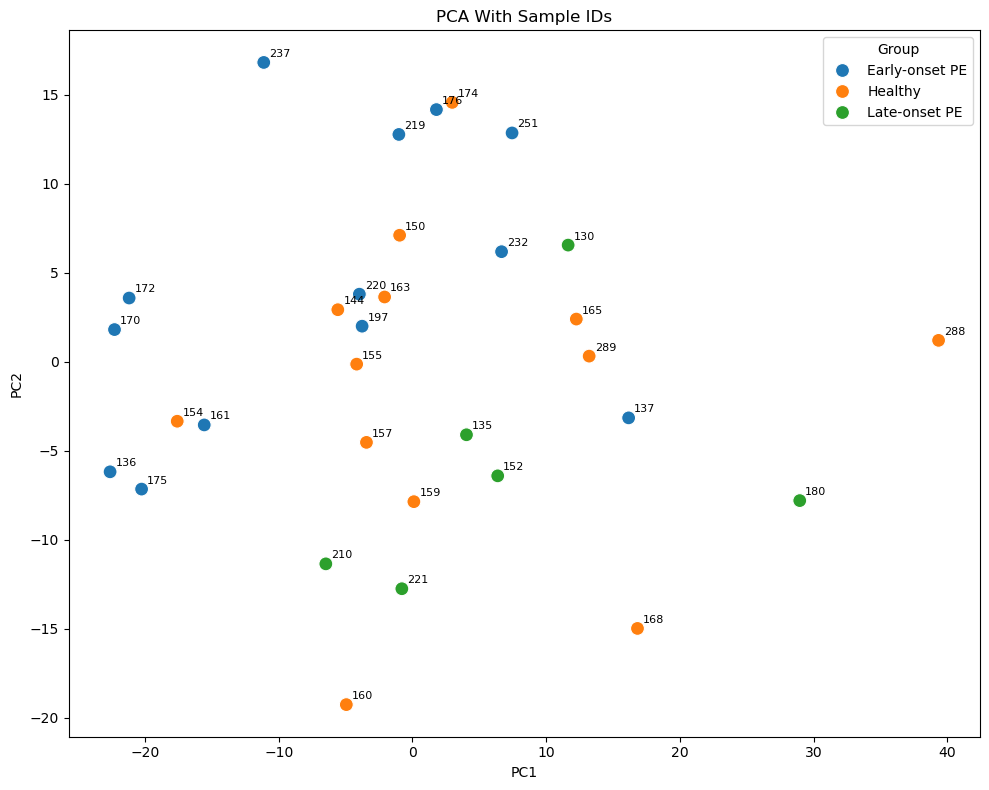

In [6]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Group",
    s=100
)

for sample_id, row in pca_df.iterrows():
    plt.annotate(
        sample_id,
        (row["PC1"], row["PC2"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.title("PCA With Sample IDs")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()

This may suggest that early onset and late onset preeclampsia may have different immune related expression profiles, but it could also be the different gestational ages

Compare early-onset and late-onset PE

In [7]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# Get sample IDs for each group
early_samples = metadata.index[
    metadata["Group"] == "Early-onset PE"
]

late_samples = metadata.index[
    metadata["Group"] == "Late-onset PE"
]

# Extract log2-normalized expression
early_expr = log_expression[early_samples]
late_expr = log_expression[late_samples]

# Welch's t-test: early-onset vs late-onset
stat, p_values = ttest_ind(
    early_expr,
    late_expr,
    axis=1,
    equal_var=False
)

# Calculate log2 fold changes
log2fc = early_expr.mean(axis=1) - late_expr.mean(axis=1)

# Multiple-testing correction
adjusted_p = multipletests(
    p_values,
    method="fdr_bh"
)[1]

# Organize results
de_results = pd.DataFrame({
    "Gene": log_expression.index,
    "log2FC": log2fc.values,
    "pvalue": p_values,
    "padj": adjusted_p
})

de_results = de_results.sort_values("padj")

print("Genes tested:", len(de_results))
print("Genes with FDR < 0.05:",
      (de_results["padj"] < 0.05).sum())

display(de_results.head(10))

Genes tested: 730
Genes with FDR < 0.05: 11


,Gene,log2FC,pvalue,padj
334,IFNL1,-0.745386,0.000005,0.003727
71,CCL17,-0.830105,0.000071,0.013372
248,ENG,1.246786,0.000092,0.013372
377,IL22RA1,-0.775608,0.000074,0.013372
130,CD3EAP,-0.458490,0.000062,0.013372
713,TREM1,1.876648,0.000171,0.020790
168,CEACAM1,-0.861637,0.000234,0.022534
657,TFEB,-0.451726,0.000247,0.022534
711,TRAF3,-0.567397,0.000499,0.040495
27,BATF,-0.843373,0.000635,0.046342


11 significant genes 

In [8]:
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

de_results.to_csv(
    results_dir / "early_vs_late_exploratory_DE.csv",
    index=False
)

print("Exploratory differential expression results saved!")

Exploratory differential expression results saved!


Volcano Plot

In [9]:
# Categorize differential expression results
de_results["Significance"] = "Not significant"

de_results.loc[
    (de_results["padj"] < 0.05) &
    (de_results["log2FC"] > 0),
    "Significance"
] = "Higher in early-onset"

de_results.loc[
    (de_results["padj"] < 0.05) &
    (de_results["log2FC"] < 0),
    "Significance"
] = "Higher in late-onset"

print(de_results["Significance"].value_counts())

# Display all 11 significant genes
significant_genes = de_results[
    de_results["padj"] < 0.05
].copy()

display(significant_genes)

Significance
Not significant          719
Higher in late-onset       9
Higher in early-onset      2
Name: count, dtype: int64


,Gene,log2FC,pvalue,padj,Significance
334,IFNL1,-0.745386,0.000005,0.003727,Higher in late-onset
71,CCL17,-0.830105,0.000071,0.013372,Higher in late-onset
248,ENG,1.246786,0.000092,0.013372,Higher in early-onset
377,IL22RA1,-0.775608,0.000074,0.013372,Higher in late-onset
130,CD3EAP,-0.458490,0.000062,0.013372,Higher in late-onset
713,TREM1,1.876648,0.000171,0.020790,Higher in early-onset
168,CEACAM1,-0.861637,0.000234,0.022534,Higher in late-onset
657,TFEB,-0.451726,0.000247,0.022534,Higher in late-onset
711,TRAF3,-0.567397,0.000499,0.040495,Higher in late-onset
27,BATF,-0.843373,0.000635,0.046342,Higher in late-onset


In [11]:
print(de_results.columns.tolist())

['Gene', 'log2FC', 'pvalue', 'padj', 'Significance', 'neg_log10_padj']


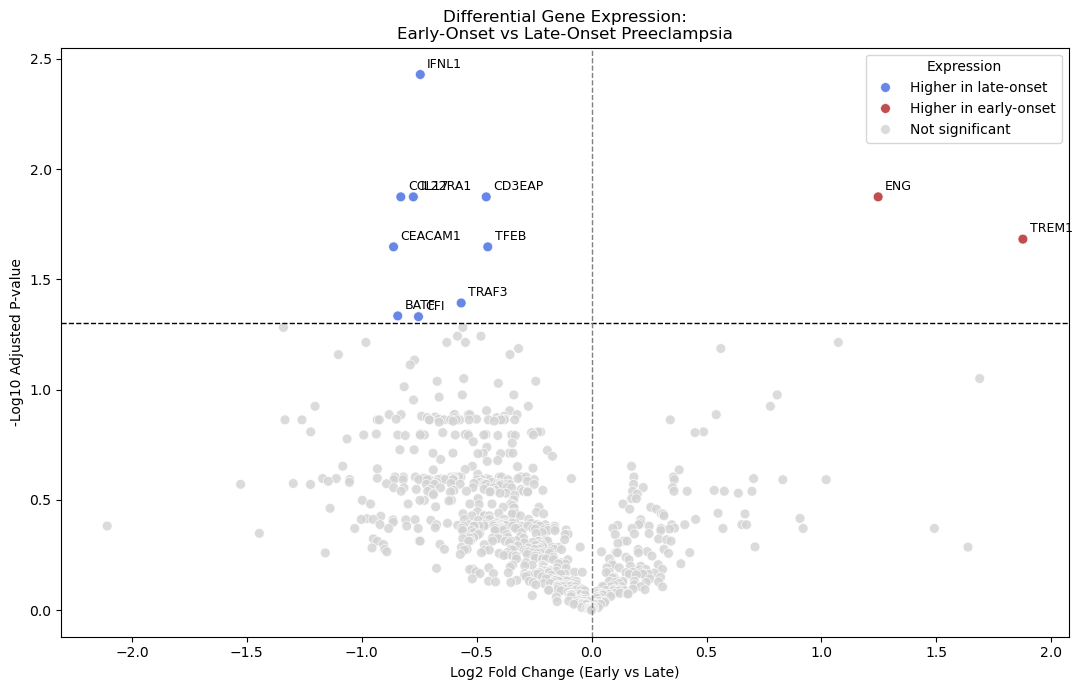

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create the missing column
de_results["neg_log10_padj"] = -np.log10(
    de_results["padj"].clip(lower=1e-300)
)

# Recreate significance labels
de_results["Significance"] = "Not significant"

de_results.loc[
    (de_results["padj"] < 0.05) &
    (de_results["log2FC"] > 0),
    "Significance"
] = "Higher in early-onset"

de_results.loc[
    (de_results["padj"] < 0.05) &
    (de_results["log2FC"] < 0),
    "Significance"
] = "Higher in late-onset"

# Select significant genes
significant_genes = de_results[
    de_results["padj"] < 0.05
].copy()

# Create volcano plot
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=de_results,
    x="log2FC",
    y="neg_log10_padj",
    hue="Significance",
    palette={
        "Higher in early-onset": "firebrick",
        "Higher in late-onset": "royalblue",
        "Not significant": "lightgray"
    },
    s=50,
    alpha=0.8
)

# Significance threshold
plt.axhline(
    -np.log10(0.05),
    color="black",
    linestyle="--",
    linewidth=1
)

# Reference line
plt.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

# Label significant genes
for _, row in significant_genes.iterrows():
    plt.annotate(
        row["Gene"],
        (row["log2FC"], row["neg_log10_padj"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title(
    "Differential Gene Expression:\n"
    "Early-Onset vs Late-Onset Preeclampsia"
)

plt.xlabel("Log2 Fold Change (Early vs Late)")
plt.ylabel("-Log10 Adjusted P-value")

plt.legend(title="Expression")

plt.tight_layout()

# Save figure
plt.savefig(
    figures_dir / "volcano_early_vs_late.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Heatmap

In [13]:
# Select genes with adjusted p-value < 0.05
significant_genes = de_results.loc[
    de_results["padj"] < 0.05, "Gene"
].tolist()

print("Significant genes:", significant_genes)
print("Total significant:", len(significant_genes))

# Arrange early-onset samples first, followed by late-onset
selected_samples = (
    metadata.index[metadata["Group"] == "Early-onset PE"].tolist()
    + metadata.index[metadata["Group"] == "Late-onset PE"].tolist()
)

# Extract log2-normalized expression
heatmap_data = log_expression.loc[
    significant_genes, selected_samples
]

# Standardize each gene for visualization
gene_means = heatmap_data.mean(axis=1)
gene_stds = heatmap_data.std(axis=1)

heatmap_z = heatmap_data.sub(
    gene_means, axis=0
).div(gene_stds, axis=0)

print("Heatmap shape:", heatmap_z.shape)

Significant genes: ['IFNL1', 'CCL17', 'ENG', 'IL22RA1', 'CD3EAP', 'TREM1', 'CEACAM1', 'TFEB', 'TRAF3', 'BATF', 'CFI']
Total significant: 11
Heatmap shape: (11, 19)


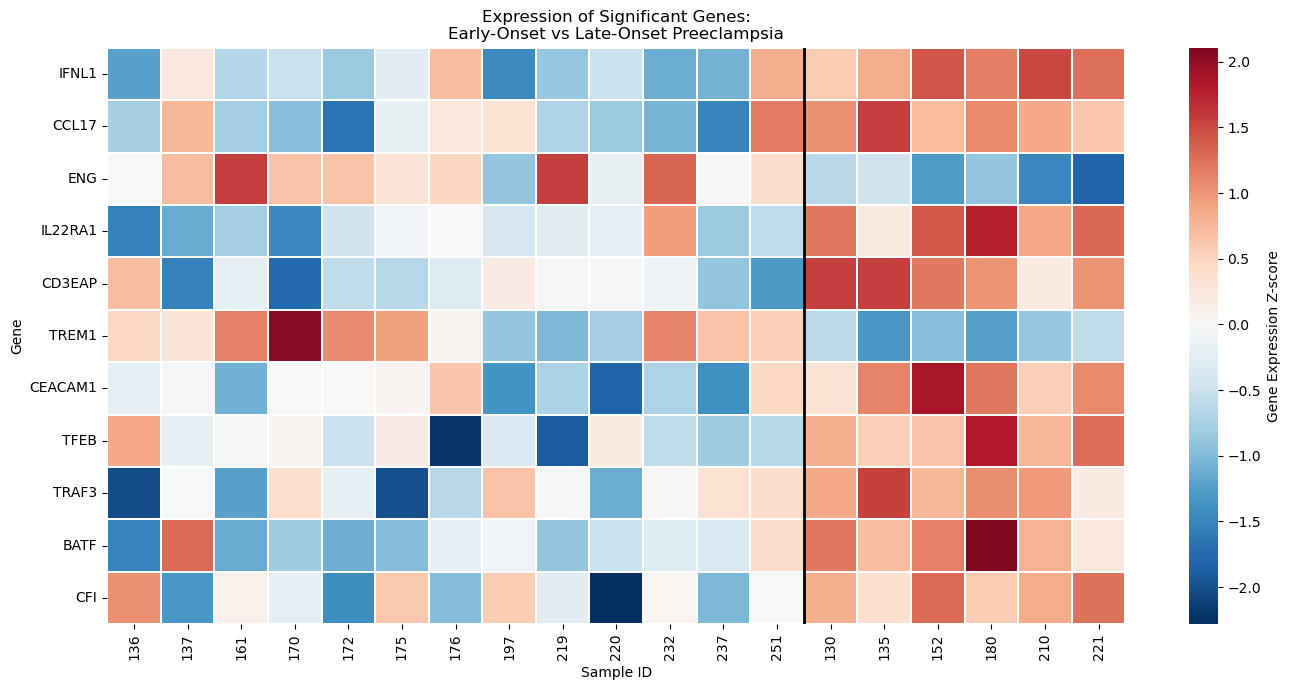

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.heatmap(
    heatmap_z,
    cmap="RdBu_r",
    center=0,
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Gene Expression Z-score"}
)

# Add dividing line between groups
plt.axvline(
    x=13,
    color="black",
    linewidth=2
)

plt.title(
    "Expression of Significant Genes:\n"
    "Early-Onset vs Late-Onset Preeclampsia"
)

plt.xlabel("Sample ID")
plt.ylabel("Gene")

plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    figures_dir / "heatmap_early_vs_late.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()